# Statistical Analysis — Binary Experiments

This notebook implements the following analysis framework:

| Block | Question | Methods | Test |
|-------|----------|---------|------|
| **A** | SP (all-combos) vs baselines | 14 methods (SP/Voting/Stacking ×{3..6} + RF + XGBoost) | Friedman → Wilcoxon + Holm |
| **B** | Best of each family | 5 methods (BEST-SP, BEST-Voting, BEST-Stacking, RF, XGBoost) | Friedman → Nemenyi |
| **C** | All-combos vs top-N | Paired per family × n | Wilcoxon + Holm |
| **Win-count** | Per-dataset dominance | All methods | Per-dataset Wilcoxon (descriptive) |

**Key methodological choices (following Demšar 2006 & García–Herrera 2008):**
- Aggregate across runs **before** any test (one value per dataset per method)
- Holm correction instead of Bonferroni (same FWER control, strictly more powerful)
- Cliff's delta as effect size (robust, non-parametric)


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import friedmanchisquare, wilcoxon, rankdata
from scikit_posthocs import posthoc_nemenyi_friedman
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.float_format", "{:.6f}".format)


C:\Users\jodivaso\AppData\Local\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Configuration

Adjust  and verify that the column names match your CSV.


In [2]:
RESULTS_CSV = "results_binary_2026_05_08_09_35_16.csv"
ALPHA = 0.05
NS = [3, 4, 5, 6]

# --- Column name mappings (CSV column → display name) ---
# All-combinations ensemble columns
ALLCOMB_TEST = {
    **{f"SP-{n}": f"sp_{n}_test" for n in NS},
    **{f"Voting-{n}": f"voting_{n}_test" for n in NS},
    **{f"Stacking-{n}": f"stacking_{n}_test" for n in NS},
    "RandomForest": "random_forest_test",
    "XGBoost": "xgboost_test",
}

# Top-N ensemble columns
TOPN_TEST = {
    **{f"SP-{n}-topN": f"topN_sp_{n}_test" for n in NS},
    **{f"Voting-{n}-topN": f"topN_voting_{n}_test" for n in NS},
    **{f"Stacking-{n}-topN": f"topN_stacking_{n}_test" for n in NS},
}

# Validation columns (for BEST computation) — all-combinations
ALLCOMB_VAL = {
    **{f"SP-{n}": f"sp_{n}_val" for n in NS},
    **{f"Voting-{n}": f"voting_{n}_val" for n in NS},
    **{f"Stacking-{n}": f"stacking_{n}_val" for n in NS},
}

# Validation columns — top-N
TOPN_VAL = {
    **{f"SP-{n}-topN": f"topN_sp_{n}_val" for n in NS},
    **{f"Voting-{n}-topN": f"topN_voting_{n}_val" for n in NS},
    **{f"Stacking-{n}-topN": f"topN_stacking_{n}_val" for n in NS},
}

DATASET_COL = "name_dataset"


## 2. Data loading, BEST computation, and aggregation

BEST is computed **per row** (per dataset × run): for each family, select the  with
the highest validation score and report the corresponding test score.  
Then we aggregate by dataset (mean across runs) to get **one observation per method per dataset**.


In [3]:
df_raw = pd.read_csv(RESULTS_CSV)
print(f"Raw data: {df_raw.shape[0]} rows, {df_raw[DATASET_COL].nunique()} datasets")


def compute_best(df, family_prefix, val_dict, test_dict):
    """For each row, pick the n with best val score and return its test score."""
    # Filter to columns belonging to this family
    family_keys = [k for k in val_dict if k.startswith(family_prefix)]
    val_cols = [val_dict[k] for k in family_keys]
    test_cols = [test_dict[k] for k in family_keys]
    best_idx = df[val_cols].values.argmax(axis=1)
    return [df.iloc[i][test_cols[idx]] for i, idx in enumerate(best_idx)]


# Compute BEST for each family (all-combinations)
df_raw["BEST-SP"] = compute_best(df_raw, "SP-", ALLCOMB_VAL, ALLCOMB_TEST)
df_raw["BEST-Voting"] = compute_best(df_raw, "Voting-", ALLCOMB_VAL, ALLCOMB_TEST)
df_raw["BEST-Stacking"] = compute_best(df_raw, "Stacking-", ALLCOMB_VAL, ALLCOMB_TEST)

# Compute BEST for each family (top-N)
df_raw["BEST-SP-topN"] = compute_best(df_raw, "SP-", TOPN_VAL, TOPN_TEST)
df_raw["BEST-Voting-topN"] = compute_best(df_raw, "Voting-", TOPN_VAL, TOPN_TEST)
df_raw["BEST-Stacking-topN"] = compute_best(df_raw, "Stacking-", TOPN_VAL, TOPN_TEST)

# --- Aggregate by dataset (mean across runs) ---
# Collect ALL relevant columns
all_test_cols = (
    list(ALLCOMB_TEST.values()) + list(TOPN_TEST.values())
    + ["BEST-SP", "BEST-Voting", "BEST-Stacking",
       "BEST-SP-topN", "BEST-Voting-topN", "BEST-Stacking-topN"]
)

df_avg = df_raw.groupby(DATASET_COL)[all_test_cols].mean()
print(f"Aggregated data: {df_avg.shape[0]} datasets (one row per dataset)")

# Build a clean DataFrame with display names as columns
rename_map = {v: k for k, v in {**ALLCOMB_TEST, **TOPN_TEST}.items()}
df_avg = df_avg.rename(columns=rename_map)
df_avg.head()


Raw data: 430 rows, 43 datasets
Aggregated data: 43 datasets (one row per dataset)


,SP-3,SP-4,SP-5,SP-6,Voting-3,Voting-4,Voting-5,Voting-6,Stacking-3,Stacking-4,Stacking-5,Stacking-6,RandomForest,XGBoost,SP-3-topN,SP-4-topN,SP-5-topN,SP-6-topN,Voting-3-topN,Voting-4-topN,Voting-5-topN,Voting-6-topN,Stacking-3-topN,Stacking-4-topN,Stacking-5-topN,Stacking-6-topN,BEST-SP,BEST-Voting,BEST-Stacking,BEST-SP-topN,BEST-Voting-topN,BEST-Stacking-topN
name_dataset,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
datasets_binary/Bioresponse.csv,0.805560,0.806801,0.809352,0.809103,0.802677,0.796545,0.807454,0.800729,0.810385,0.807778,0.810829,0.811913,0.822802,0.813883,0.801625,0.805034,0.805384,0.809103,0.801695,0.796668,0.806844,0.800729,0.803515,0.805080,0.809962,0.811913,0.809339,0.803935,0.808762,0.809244,0.803727,0.809254
datasets_binary/Contaminant.csv,0.936891,0.938225,0.933285,0.933007,0.936901,0.923903,0.922616,0.908358,0.936927,0.939190,0.937807,0.937844,0.891573,0.912044,0.934941,0.935164,0.932000,0.933007,0.932488,0.916813,0.916998,0.908358,0.935528,0.937664,0.937235,0.937844,0.933179,0.936901,0.940031,0.932231,0.932121,0.936163
datasets_binary/ECG5000.csv,0.991958,0.992470,0.992297,0.992212,0.992650,0.993155,0.993164,0.993069,0.991290,0.991634,0.992485,0.992827,0.993420,0.992909,0.991789,0.992134,0.992297,0.992212,0.992232,0.992728,0.992909,0.993069,0.992317,0.991636,0.992738,0.992827,0.992470,0.992988,0.991290,0.992212,0.993078,0.992058
datasets_binary/FICO.csv,0.725476,0.726407,0.725320,0.725115,0.718416,0.711748,0.716446,0.713486,0.713779,0.716835,0.715959,0.717412,0.712052,0.702128,0.725332,0.724472,0.725245,0.725115,0.716545,0.711900,0.716996,0.713486,0.717508,0.717458,0.717138,0.717412,0.725585,0.718416,0.713317,0.725171,0.716602,0.717475
datasets_binary/Insurance.csv,0.305446,0.306821,0.306821,0.306821,0.154977,0.045869,0.045869,0.005063,0.000000,0.000000,0.000000,0.000000,0.005151,0.220891,0.303605,0.306821,0.306821,0.306821,0.154977,0.045869,0.045869,0.005063,0.000000,0.000000,0.000000,0.000000,0.306821,0.154977,0.000000,0.306821,0.154977,0.000000


## 3. Statistical helper functions


In [4]:
def holm_correction(pvalues):
    """Holm step-down correction. Controls FWER like Bonferroni but is strictly more powerful."""
    pvals = np.asarray(pvalues, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    sorted_p = pvals[order]
    adjusted = np.minimum(sorted_p * np.arange(n, 0, -1), 1.0)
    # Enforce monotonicity (cumulative maximum)
    for i in range(1, n):
        adjusted[i] = max(adjusted[i], adjusted[i - 1])
    result = np.empty(n)
    result[order] = adjusted
    return result


def cliffs_delta(x, y):
    """Paired Cliff's delta (nonparametric effect size).

    Interpretation (Romano et al. 2006):
        |d| < 0.147  negligible
        |d| < 0.33   small
        |d| < 0.474  medium
        |d| >= 0.474 large
    """
    d = np.asarray(x) - np.asarray(y)
    return (np.sum(d > 0) - np.sum(d < 0)) / len(d)


def cliffs_delta_label(d):
    """Return a human-readable label for a Cliff's delta value."""
    ad = abs(d)
    if ad < 0.147:
        return "negligible"
    elif ad < 0.33:
        return "small"
    elif ad < 0.474:
        return "medium"
    else:
        return "large"


def pairwise_wilcoxon(df, method_cols, control_prefix=None):
    """Pairwise Wilcoxon signed-rank tests with Holm correction.

    Parameters
    ----------
    df : DataFrame with one row per dataset, columns = method names.
    method_cols : list of column names (display names) to compare.
    control_prefix : if given, only compare methods whose name starts with
                     this prefix against all others. If None, compare all pairs.

    Returns
    -------
    DataFrame with columns: Method1, Method2, p_raw, p_holm, cliff_d, magnitude, Sig.
    """
    pairs, p_raw, deltas = [], [], []

    if control_prefix:
        controls = [m for m in method_cols if m.startswith(control_prefix)]
        others = [m for m in method_cols if not m.startswith(control_prefix)]
        combos = [(c, o) for c in controls for o in others]
    else:
        from itertools import combinations
        combos = list(combinations(method_cols, 2))

    for m1, m2 in combos:
        x, y = df[m1].values, df[m2].values
        diff = x - y
        if np.all(diff == 0):
            p = 1.0
        else:
            _, p = wilcoxon(x, y, alternative="two-sided")
        pairs.append((m1, m2))
        p_raw.append(p)
        deltas.append(cliffs_delta(x, y))

    p_holm = holm_correction(p_raw)

    result = pd.DataFrame({
        "Method 1": [p[0] for p in pairs],
        "Method 2": [p[1] for p in pairs],
        "p (raw)": p_raw,
        "p (Holm)": p_holm,
        "Cliff d": deltas,
        "Magnitude": [cliffs_delta_label(d) for d in deltas],
        "Sig.": ["Yes" if p < ALPHA else "No" for p in p_holm],
    })
    return result.sort_values("p (Holm)").reset_index(drop=True)


def friedman_test(df, method_cols):
    """Run Friedman test and print result."""
    arrays = [df[m].values for m in method_cols]
    stat, p = friedmanchisquare(*arrays)
    print(f"Friedman χ² = {stat:.4f},  p = {p:.2e}")
    if p < ALPHA:
        print(f"→ Significant differences detected (p < {ALPHA})")
    else:
        print(f"→ No significant differences (p ≥ {ALPHA})")
    return stat, p


---
## Block A — Main comparison (all combinations)

14 methods: SP-{3..6}, Voting-{3..6}, Stacking-{3..6}, RF, XGBoost.  
Friedman omnibus → if significant → Wilcoxon pairwise (SP vs all others) with Holm correction.


In [5]:
# Methods for Block A (all-combinations + baselines)
block_a_methods = [
    *[f"SP-{n}" for n in NS],
    *[f"Voting-{n}" for n in NS],
    *[f"Stacking-{n}" for n in NS],
    "RandomForest", "XGBoost",
]

print("="*60)
print("BLOCK A: Friedman omnibus test")
print("="*60)
stat_a, p_a = friedman_test(df_avg, block_a_methods)

if p_a < ALPHA:
    print("\n" + "="*60)
    print("BLOCK A: Pairwise Wilcoxon (SP vs others) + Holm correction")
    print("="*60)
    table_a = pairwise_wilcoxon(df_avg, block_a_methods, control_prefix="SP-")
    print(table_a.to_string(index=False))

    print("\n" + "="*60)
    print("BLOCK A: Mean F1 across all datasets")
    print("="*60)
    means = df_avg[block_a_methods].mean().sort_values(ascending=False)
    print(means.to_string())

    print("\n" + "="*60)
    print("BLOCK A: Mean ranks (lower = better)")
    print("="*60)
    ranks = df_avg[block_a_methods].rank(axis=1, ascending=False)
    mean_ranks = ranks.mean().sort_values()
    print(mean_ranks.to_string())


BLOCK A: Friedman omnibus test
Friedman χ² = 154.3775,  p = 2.70e-26
→ Significant differences detected (p < 0.05)

BLOCK A: Pairwise Wilcoxon (SP vs others) + Holm correction
Method 1     Method 2  p (raw)  p (Holm)   Cliff d  Magnitude Sig.
    SP-5     Voting-6 0.000000  0.000000  0.767442      large  Yes
    SP-5     Voting-4 0.000000  0.000000  0.720930      large  Yes
    SP-5     Voting-5 0.000000  0.000000  0.674419      large  Yes
    SP-6     Voting-6 0.000000  0.000002  0.813953      large  Yes
    SP-3     Voting-6 0.000000  0.000003  0.790698      large  Yes
    SP-6     Voting-4 0.000000  0.000003  0.813953      large  Yes
    SP-4     Voting-4 0.000000  0.000003  0.697674      large  Yes
    SP-4     Voting-6 0.000000  0.000003  0.744186      large  Yes
    SP-3     Voting-4 0.000000  0.000012  0.558140      large  Yes
    SP-5     Voting-3 0.000001  0.000033  0.488372      large  Yes
    SP-6     Voting-5 0.000001  0.000036  0.627907      large  Yes
    SP-4     Voting-

---
## Block B — BEST of each family

5 methods: BEST-SP, BEST-Voting, BEST-Stacking, RandomForest, XGBoost.  
With only 5 methods Nemenyi has reasonable power.  
Produces a Critical Difference–style comparison.


BLOCK B: Friedman omnibus test
Friedman χ² = 33.3867,  p = 9.95e-07
→ Significant differences detected (p < 0.05)

Nemenyi p-value matrix:
               BEST-SP  BEST-Voting  BEST-Stacking  RandomForest  XGBoost
BEST-SP       1.000000     0.018300       0.244100      0.000000 0.002800
BEST-Voting   0.018300     1.000000       0.844900      0.128500 0.982500
BEST-Stacking 0.244100     0.844900       1.000000      0.006600 0.517700
RandomForest  0.000000     0.128500       0.006600      1.000000 0.369200
XGBoost       0.002800     0.982500       0.517700      0.369200 1.000000


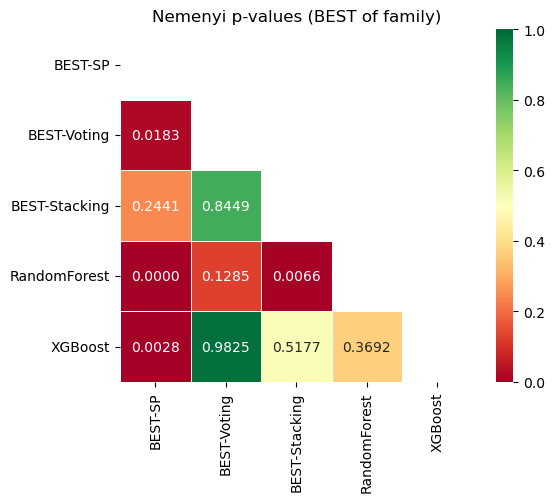


Mean ranks (lower = better):
BEST-SP         2.034884
BEST-Stacking   2.732558
BEST-Voting     3.081395
XGBoost         3.267442
RandomForest    3.883721

BLOCK B: Wilcoxon pairwise (BEST-SP vs others) + Holm
Method 1      Method 2  p (raw)  p (Holm)  Cliff d Magnitude Sig.
 BEST-SP   BEST-Voting 0.000003  0.000011 0.558140     large  Yes
 BEST-SP  RandomForest 0.000003  0.000011 0.581395     large  Yes
 BEST-SP       XGBoost 0.000050  0.000099 0.511628     large  Yes
 BEST-SP BEST-Stacking 0.005832  0.005832 0.279070     small  Yes

Mean F1:
BEST-SP         0.788866
XGBoost         0.773048
BEST-Voting     0.771706
BEST-Stacking   0.767989
RandomForest    0.731604


In [6]:
block_b_methods = ["BEST-SP", "BEST-Voting", "BEST-Stacking", "RandomForest", "XGBoost"]

print("="*60)
print("BLOCK B: Friedman omnibus test")
print("="*60)
stat_b, p_b = friedman_test(df_avg, block_b_methods)

if p_b < ALPHA:
    # Nemenyi post-hoc
    scores_matrix = df_avg[block_b_methods].values
    nemenyi = posthoc_nemenyi_friedman(scores_matrix)
    nemenyi.index = block_b_methods
    nemenyi.columns = block_b_methods

    print("\nNemenyi p-value matrix:")
    print(nemenyi.round(4).to_string())

    # Heatmap
    fig, ax = plt.subplots(figsize=(6, 5))
    mask = np.triu(np.ones_like(nemenyi, dtype=bool), k=0)
    sns.heatmap(nemenyi, annot=True, fmt=".4f", cmap="RdYlGn",
                mask=mask, vmin=0, vmax=1, ax=ax,
                linewidths=0.5, square=True)
    ax.set_title("Nemenyi p-values (BEST of family)")
    plt.tight_layout()
    plt.savefig("nemenyi_best_of_family.pdf", bbox_inches="tight", dpi=300)
    plt.show()

    # Mean ranks
    ranks_b = df_avg[block_b_methods].rank(axis=1, ascending=False)
    mean_ranks_b = ranks_b.mean().sort_values()
    print("\nMean ranks (lower = better):")
    print(mean_ranks_b.to_string())

    # Also Wilcoxon + Holm for completeness
    print("\n" + "="*60)
    print("BLOCK B: Wilcoxon pairwise (BEST-SP vs others) + Holm")
    print("="*60)
    table_b = pairwise_wilcoxon(df_avg, block_b_methods, control_prefix="BEST-SP")
    print(table_b.to_string(index=False))

    # Mean F1
    print("\nMean F1:")
    print(df_avg[block_b_methods].mean().sort_values(ascending=False).to_string())


---
## Block C — All combinations vs top-N

For each family and each , a paired Wilcoxon test comparing the all-combinations
variant against the top-N variant.  
3 families × 4 values of n = 12 comparisons → Holm correction.


In [7]:
print("="*60)
print("BLOCK C: All-combinations vs top-N")
print("="*60)

pairs_c, pvals_c, deltas_c = [], [], []

for family in ["SP", "Voting", "Stacking"]:
    for n in NS:
        allcomb_name = f"{family}-{n}"
        topn_name = f"{family}-{n}-topN"
        x = df_avg[allcomb_name].values
        y = df_avg[topn_name].values
        diff = x - y
        if np.all(diff == 0):
            p = 1.0
        else:
            _, p = wilcoxon(x, y, alternative="two-sided")
        pairs_c.append((allcomb_name, topn_name))
        pvals_c.append(p)
        deltas_c.append(cliffs_delta(x, y))

p_holm_c = holm_correction(pvals_c)

table_c = pd.DataFrame({
    "All-combos": [p[0] for p in pairs_c],
    "Top-N": [p[1] for p in pairs_c],
    "p (raw)": pvals_c,
    "p (Holm)": p_holm_c,
    "Cliff d": deltas_c,
    "Magnitude": [cliffs_delta_label(d) for d in deltas_c],
    "Sig.": ["Yes" if p < ALPHA else "No" for p in p_holm_c],
})
print(table_c.to_string(index=False))


BLOCK C: All-combinations vs top-N
All-combos           Top-N  p (raw)  p (Holm)   Cliff d  Magnitude Sig.
      SP-3       SP-3-topN 0.020054  0.180482  0.325581      small   No
      SP-4       SP-4-topN 0.003539  0.042465  0.488372      large  Yes
      SP-5       SP-5-topN 0.017891  0.178909  0.325581      small   No
      SP-6       SP-6-topN 1.000000  1.000000  0.000000 negligible   No
  Voting-3   Voting-3-topN 0.613285  1.000000  0.162791      small   No
  Voting-4   Voting-4-topN 0.238680  1.000000 -0.093023 negligible   No
  Voting-5   Voting-5-topN 0.895749  1.000000  0.069767 negligible   No
  Voting-6   Voting-6-topN 1.000000  1.000000  0.000000 negligible   No
Stacking-3 Stacking-3-topN 0.078691  0.629531  0.348837     medium   No
Stacking-4 Stacking-4-topN 0.004416  0.048574  0.302326      small  Yes
Stacking-5 Stacking-5-topN 0.252495  1.000000  0.023256 negligible   No
Stacking-6 Stacking-6-topN 1.000000  1.000000  0.000000 negligible   No


---
## Win-count matrix

For each pair of algorithms and each dataset, a Wilcoxon signed-rank test is
performed on the raw (non-averaged) repetitions.  If the difference is significant
at α = 0.05, the method with the higher mean is marked as the winner.

**Note:** with only 10 repetitions per dataset the test has limited power, so these
counts are conservative (a lower bound on actual wins). This is a descriptive
summary, not a formally controlled hypothesis test.


In [8]:
def win_count_matrix(df_raw, method_cols, dataset_col, alpha=0.05):
    """Build the win-count matrix using per-dataset Wilcoxon tests.

    For each (dataset, pair), run a Wilcoxon signed-rank test on the raw
    repetitions.  If significant, the method with higher mean wins.
    """
    methods = list(method_cols.keys())   # display names
    csv_cols = list(method_cols.values()) # CSV column names
    n = len(methods)
    matrix = pd.DataFrame(np.zeros((n, n), dtype=int),
                          index=methods, columns=methods)

    for ds in df_raw[dataset_col].unique():
        sub = df_raw[df_raw[dataset_col] == ds]
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                xi = sub[csv_cols[i]].values
                xj = sub[csv_cols[j]].values
                diff = xi - xj
                if len(diff) < 2 or np.all(diff == 0):
                    continue
                try:
                    _, p = wilcoxon(xi, xj, alternative="two-sided")
                    if p < alpha and xi.mean() > xj.mean():
                        matrix.iloc[i, j] += 1
                except Exception:
                    pass  # identical values → draw
    return matrix


# Select which methods to include in the win-count matrix
wc_methods = {
    **{f"SP-{n}": f"sp_{n}_test" for n in NS},
    "BEST-SP": "BEST-SP",
    **{f"Voting-{n}": f"voting_{n}_test" for n in NS},
    "BEST-Voting": "BEST-Voting",
    **{f"Stacking-{n}": f"stacking_{n}_test" for n in NS},
    "BEST-Stacking": "BEST-Stacking",
    "RandomForest": "random_forest_test",
    "XGBoost": "xgboost_test",
}

print("Computing win-count matrix (this may take a moment)...")
wc = win_count_matrix(df_raw, wc_methods, DATASET_COL, alpha=ALPHA)
print("Done.")
print(wc)


Computing win-count matrix (this may take a moment)...
Done.
               SP-3  SP-4  SP-5  SP-6  BEST-SP  Voting-3  Voting-4  Voting-5  \
SP-3              0     0     1     2        1        19        31        28   
SP-4              2     0     0     1        0        17        29        28   
SP-5              1     0     0     1        1        19        27        27   
SP-6              1     0     0     0        0        19        26        28   
BEST-SP           2     0     0     0        0        21        29        27   
Voting-3          2     0     0     0        0         0        22        17   
Voting-4          1     0     0     0        0         0         0         2   
Voting-5          1     2     0     0        0         0        18         0   
Voting-6          1     0     0     0        0         0         0         0   
BEST-Voting       2     0     0     0        0         0        21        17   
Stacking-3        4     3     2     4        4        10   

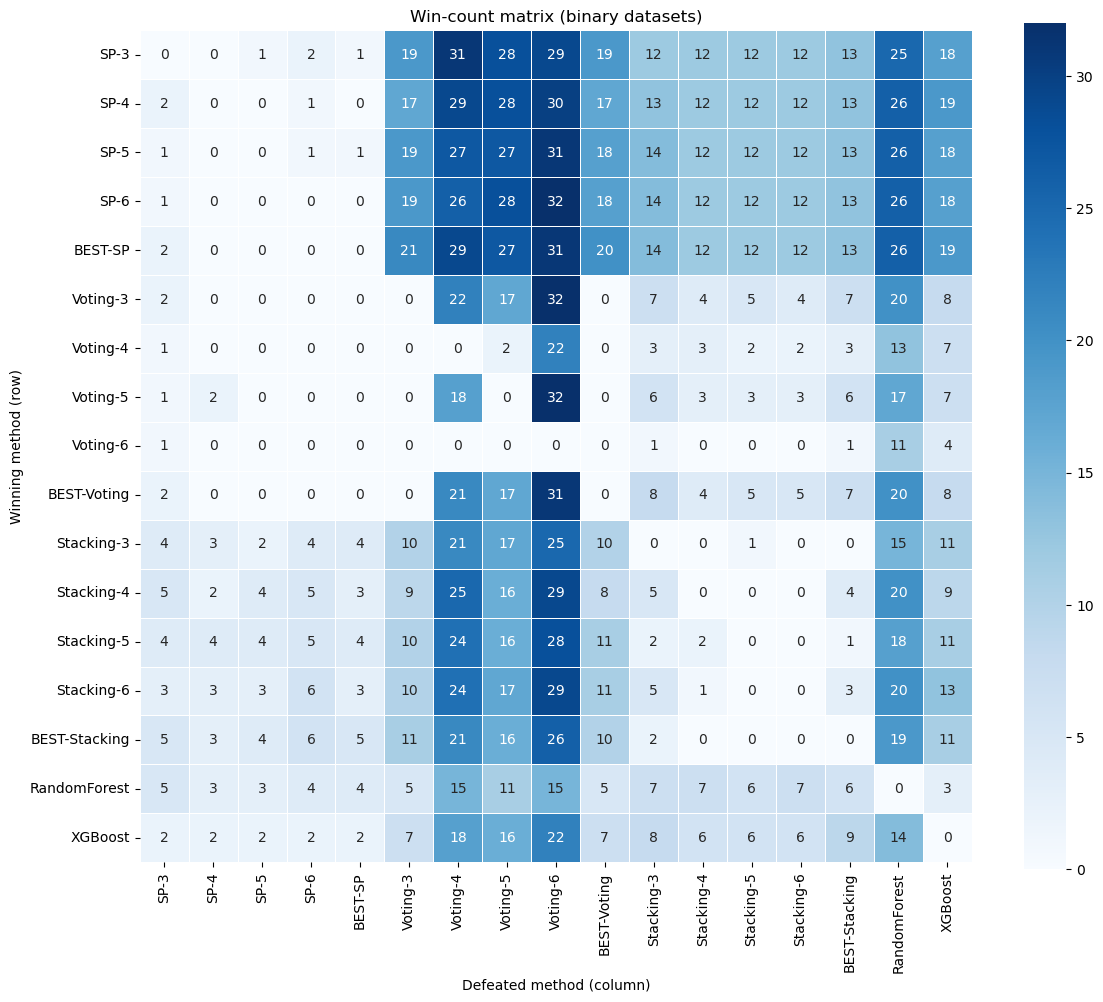

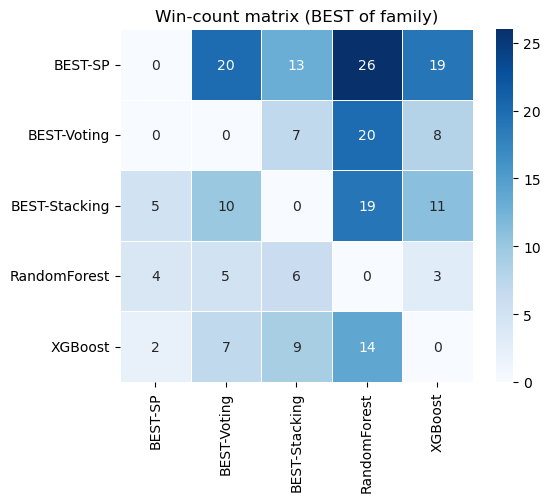

In [9]:
# Full win-count heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(wc, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (binary datasets)")
ax.set_xlabel("Defeated method (column)")
ax.set_ylabel("Winning method (row)")
plt.tight_layout()
plt.savefig("win_count_matrix_full_binary.pdf", bbox_inches="tight", dpi=300)
plt.show()

# Compact heatmap (BEST + baselines only)
compact_methods = ["BEST-SP", "BEST-Voting", "BEST-Stacking", "RandomForest", "XGBoost"]
wc_compact = wc.loc[compact_methods, compact_methods]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(wc_compact, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (BEST of family)")
plt.tight_layout()
plt.savefig("win_count_matrix_small_binary.pdf", bbox_inches="tight", dpi=300)
plt.show()


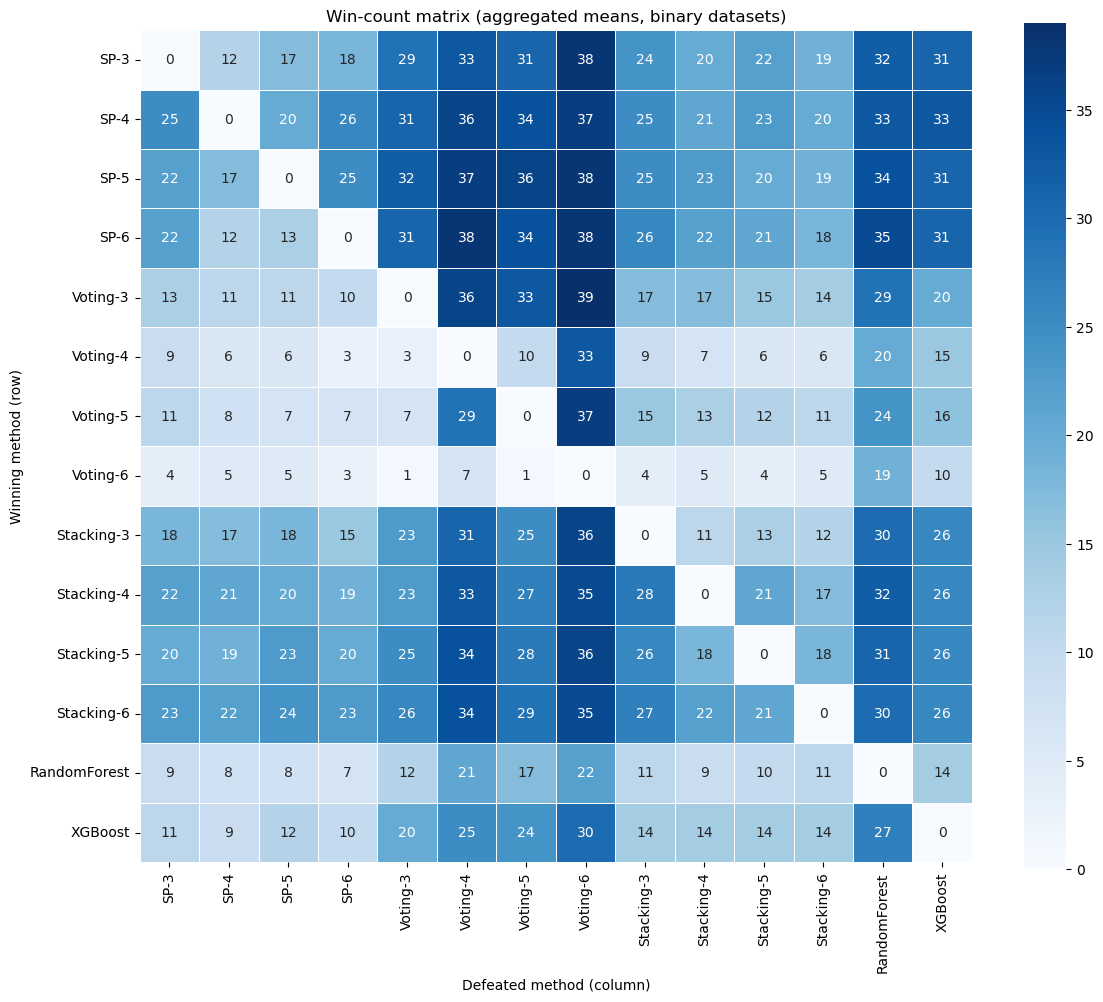

In [10]:
# ==============================================================
# Win-count matrix — Option 2: based on aggregated data (df_avg)
# ==============================================================
# For each pair (A, B) and each dataset, simply checks whether
# A > B using the mean F1 across the 10 runs. No per-dataset
# significance test — the statistical significance is already
# established by the Wilcoxon tests in Blocks A and B.
#
# Advantages over the per-dataset Wilcoxon version:
#   • No multiple testing problem (no 43 tests per pair)
#   • Not limited by the low power of n=10 per dataset
#   • Directly interpretable: "A scored higher in X out of 43 datasets"
# ==============================================================

def win_count_matrix_aggregated(df_avg, method_cols):
    """Win-count matrix based on dataset-level mean comparisons.

    Parameters
    ----------
    df_avg : DataFrame with one row per dataset, columns = display-name methods.
    method_cols : list of column names to include.

    Returns
    -------
    DataFrame (n_methods × n_methods) where cell (i, j) = number of datasets
    in which method i scored strictly higher than method j.
    """
    n = len(method_cols)
    matrix = pd.DataFrame(
        np.zeros((n, n), dtype=int),
        index=method_cols, columns=method_cols
    )
    vals = df_avg[method_cols].values  # shape (n_datasets, n_methods)

    for i in range(n):
        for j in range(n):
            if i != j:
                matrix.iloc[i, j] = int(np.sum(vals[:, i] > vals[:, j]))
    return matrix


# --- Compute ---
wc2_methods = block_a_methods  # or any subset you want
wc2 = win_count_matrix_aggregated(df_avg, wc2_methods)

# --- Heatmap ---
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(wc2, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (aggregated means, binary datasets)")
ax.set_xlabel("Defeated method (column)")
ax.set_ylabel("Winning method (row)")
plt.tight_layout()
plt.savefig("win_count_matrix_aggregated_binary.pdf", bbox_inches="tight", dpi=300)
plt.show()

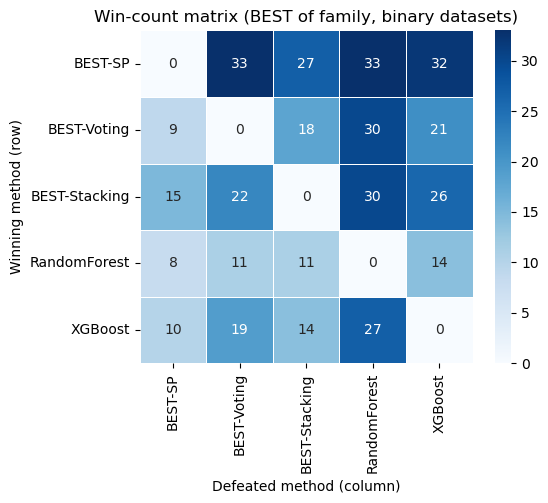

In [11]:
# --- Win-count matrix (BEST of family) ---
wc2_best_methods = ["BEST-SP", "BEST-Voting", "BEST-Stacking", "RandomForest", "XGBoost"]
wc2_best = win_count_matrix_aggregated(df_avg, wc2_best_methods)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(wc2_best, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (BEST of family, binary datasets)")
ax.set_xlabel("Defeated method (column)")
ax.set_ylabel("Winning method (row)")
plt.tight_layout()
plt.savefig("win_count_matrix_best_binary.pdf", bbox_inches="tight", dpi=300)
plt.show()

---
## Rank distribution boxplot


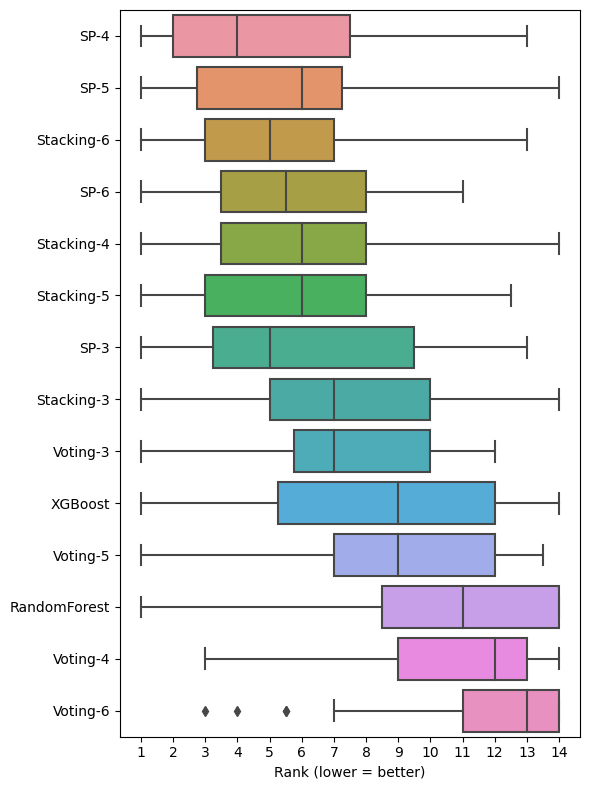

In [12]:
# Rank distribution across datasets
rank_cols = block_a_methods
rankings = df_avg[rank_cols].rank(axis=1, ascending=False, method="average")
order = rankings.mean().sort_values().index

fig, ax = plt.subplots(figsize=(6, 8))
sns.boxplot(data=rankings[order], orient="h", ax=ax)
ax.set_xlabel("Rank (lower = better)")
ax.set_ylabel("")
ax.set_xticks(range(1, len(rank_cols) + 1))
plt.tight_layout()
plt.savefig("rank_boxplot_binary.pdf", bbox_inches="tight", dpi=300)
plt.show()


---
## LaTeX-ready tables

Tables formatted for direct inclusion in the paper.


In [13]:
def to_latex_comparison(table, caption, label):
    """Print a pairwise comparison table in LaTeX format."""
    cols = ["Method 1", "Method 2", "p (Holm)", "Cliff d", "Magnitude", "Sig."]
    t = table[cols].copy()
    t["p (Holm)"] = t["p (Holm)"].apply(
        lambda x: f"{x:.4f}" if x >= 0.0001 else "<0.0001"
    )
    t["Cliff d"] = t["Cliff d"].apply(lambda x: f"{x:.4f}")
    latex = t.to_latex(index=False, escape=False, column_format="llrlll")
    print(f"\\begin{{table*}}[ht]")
    print(f"\\centering")
    print(f"\\caption{{{caption}}}")
    print(f"\\label{{{label}}}")
    print(latex)
    print(f"\\end{{table*}}")
    print()


def to_latex_mean_f1(df, methods, caption, label):
    """Print a mean-F1 table in LaTeX format."""
    means = df[methods].mean().sort_values(ascending=False)
    t = pd.DataFrame({"Method": means.index, "Mean F1": means.values})
    t["Mean F1"] = t["Mean F1"].apply(lambda x: f"{x:.6f}")
    latex = t.to_latex(index=False, escape=False, column_format="lr")
    print(f"\\begin{{table}}[ht]")
    print(f"\\centering")
    print(f"\\caption{{{caption}}}")
    print(f"\\label{{{label}}}")
    print(latex)
    print(f"\\end{{table}}")
    print()


print("=" * 60)
print("LaTeX: Block A — Pairwise comparison")
print("=" * 60)
to_latex_comparison(
    table_a,
    "Pairwise Wilcoxon tests (SP vs others) with Holm correction on binary datasets.",
    "tab:wilcoxon_binary"
)

print("=" * 60)
print("LaTeX: Block A — Mean F1")
print("=" * 60)
to_latex_mean_f1(
    df_avg, block_a_methods,
    "Mean F1-score across all binary datasets.",
    "tab:mean_binary"
)


LaTeX: Block A — Pairwise comparison
\begin{table*}[ht]
\centering
\caption{Pairwise Wilcoxon tests (SP vs others) with Holm correction on binary datasets.}
\label{tab:wilcoxon_binary}
\begin{tabular}{llrlll}
\toprule
Method 1 & Method 2 & p (Holm) & Cliff d & Magnitude & Sig. \\
\midrule
SP-5 & Voting-6 & <0.0001 & 0.7674 & large & Yes \\
SP-5 & Voting-4 & <0.0001 & 0.7209 & large & Yes \\
SP-5 & Voting-5 & <0.0001 & 0.6744 & large & Yes \\
SP-6 & Voting-6 & <0.0001 & 0.8140 & large & Yes \\
SP-3 & Voting-6 & <0.0001 & 0.7907 & large & Yes \\
SP-6 & Voting-4 & <0.0001 & 0.8140 & large & Yes \\
SP-4 & Voting-4 & <0.0001 & 0.6977 & large & Yes \\
SP-4 & Voting-6 & <0.0001 & 0.7442 & large & Yes \\
SP-3 & Voting-4 & <0.0001 & 0.5581 & large & Yes \\
SP-5 & Voting-3 & <0.0001 & 0.4884 & large & Yes \\
SP-6 & Voting-5 & <0.0001 & 0.6279 & large & Yes \\
SP-4 & Voting-5 & <0.0001 & 0.6047 & large & Yes \\
SP-5 & RandomForest & <0.0001 & 0.6047 & large & Yes \\
SP-6 & RandomForest & <0.0001 

In [15]:
# =============================================================================
# CELL 23 — Timing table + LaTeX tables for Blocks B and C
# =============================================================================
# Assumes: df_raw, NS, ALPHA, table_b, table_c, RESULTS_CSV are already defined
# Assumes: to_latex_comparison() is already defined (Cell 22)
# =============================================================================

# ─────────────────────────────────────────────────────────────────────────────
# PART 1: Timing table (Median + IQR)
# ─────────────────────────────────────────────────────────────────────────────

# Time column mappings: (display_name, csv_column)
time_rows = []

# SP all-combos
for n in NS:
    time_rows.append(("Series-Parallel", "All-combos", n, f"time_sp_{n}"))
# SP top-N
for n in NS:
    time_rows.append(("Series-Parallel", "Top-N", n, f"time_topN_sp_{n}"))
# Stacking all-combos
for n in NS:
    time_rows.append(("Stacking", "All-combos", n, f"time_stacking_{n}"))
# Stacking top-N
for n in NS:
    time_rows.append(("Stacking", "Top-N", n, f"time_topN_stacking_{n}"))
# Baselines (no N)
time_rows.append(("Random Forest", "—", "—", "time_random_forest"))
time_rows.append(("XGBoost", "—", "—", "time_xgboost"))

# BEST rows: sum of times across all N (you need to run all N to select the best)
best_time_rows = []
for family, prefix in [("Series-Parallel", "sp"), ("Stacking", "stacking")]:
    for variant, col_tpl in [("All-combos", "time_{prefix}_{n}")]:
        cols = [col_tpl.format(prefix=prefix, n=n) for n in NS]
        if all(c in df_raw.columns for c in cols):
            best_time_rows.append((family, variant, cols))
        else:
            missing = [c for c in cols if c not in df_raw.columns]
            print(f"WARNING: Missing columns for BEST-{family} {variant}: {missing}")

# Build the table
timing_records = []
for method, variant, n, col in time_rows:
    if col in df_raw.columns:
        values = df_raw[col].dropna()
        timing_records.append({
            "Method": method,
            "Variant": variant,
            "N": n,
            "Mean (s)": values.mean(),
            "Median (s)": values.median(),
        })
    else:
        print(f"WARNING: Column '{col}' not found in CSV")

# Add BEST rows (sum across all N per row, then mean/median of the sums)
for method, variant, cols in best_time_rows:
    sum_values = df_raw[cols].sum(axis=1).dropna()
    timing_records.append({
        "Method": f"BEST-{method.replace('Series-Parallel', 'SP')}",
        "Variant": variant,
        "N": "3–6",
        "Mean (s)": sum_values.mean(),
        "Median (s)": sum_values.median(),
    })

df_time = pd.DataFrame(timing_records)

print("=" * 70)
print("TIMING TABLE (Mean + Median across all datasets × runs)")
print("=" * 70)
print(df_time.to_string(index=False))
print()

# --- LaTeX output ---
print("=" * 70)
print("LaTeX: Timing table")
print("=" * 70)

def format_time(x):
    """Format time: use 4 decimal places for very small values, 2 otherwise."""
    if x < 0.01:
        return f"{x:.4f}"
    elif x < 1:
        return f"{x:.3f}"
    else:
        return f"{x:.2f}"

print(r"\begin{table}[!tb]")
print(r"\centering")
print(r"\caption{Mean and median time for each method across all binary datasets and runs. "
      r"Times for ensemble methods exclude base learner training. "
      r"Times for Random Forest and XGBoost include their Bayesian hyperparameter optimization.}")
print(r"\label{tab:time_binary}")
print(r"\begin{tabular}{llcrr}")
print(r"\toprule")
print(r"Method & Variant & $N$ & Mean (s) & Median (s) \\")
print(r"\midrule")

prev_method = None
for _, row in df_time.iterrows():
    # Add a midrule between method groups
    if prev_method is not None and row["Method"] != prev_method:
        print(r"\midrule")
    prev_method = row["Method"]

    n_str = str(row["N"]) if row["N"] != "—" else "—"
    mean_str = format_time(row["Mean (s)"])
    med_str = format_time(row["Median (s)"])
    print(f"{row['Method']} & {row['Variant']} & {n_str} & {mean_str} & {med_str} \\\\")

print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")
print()


# ─────────────────────────────────────────────────────────────────────────────
# PART 2: LaTeX table for Block B (BEST of each family)
# ─────────────────────────────────────────────────────────────────────────────

print("=" * 70)
print("LaTeX: Block B — BEST of each family (Wilcoxon + Holm)")
print("=" * 70)

# table_b was computed in Cell 11. Re-generate if needed:
try:
    _ = table_b
except NameError:
    # Recompute if not in scope
    block_b_methods = ["BEST-SP", "BEST-Voting", "BEST-Stacking", "RandomForest", "XGBoost"]
    table_b = pairwise_wilcoxon(df_avg, block_b_methods, control_prefix="BEST-SP")

to_latex_comparison(
    table_b,
    "Block B: Pairwise Wilcoxon tests (BEST-SP vs others) with Holm correction on binary datasets.",
    "tab:block_b_binary"
)

# Also: Nemenyi p-value matrix as LaTeX
print("=" * 70)
print("LaTeX: Block B — Nemenyi p-value matrix")
print("=" * 70)

block_b_methods = ["BEST-SP", "BEST-Voting", "BEST-Stacking", "RandomForest", "XGBoost"]
scores_matrix = df_avg[block_b_methods].values
nemenyi = posthoc_nemenyi_friedman(scores_matrix)
nemenyi.index = block_b_methods
nemenyi.columns = block_b_methods

# Lower-triangular only
print(r"\begin{table}[!tb]")
print(r"\centering")
print(r"\caption{Nemenyi post-hoc p-values for Block B (BEST of each family) on binary datasets.}")
print(r"\label{tab:nemenyi_binary}")
n_methods = len(block_b_methods)
col_fmt = "l" + "r" * n_methods
print(f"\\begin{{tabular}}{{{col_fmt}}}")
print(r"\toprule")
header = " & ".join([""] + [m.replace("BEST-", "B-") for m in block_b_methods])
print(header + r" \\")
print(r"\midrule")

for i, m1 in enumerate(block_b_methods):
    row_label = m1.replace("BEST-", "B-")
    cells = []
    for j, m2 in enumerate(block_b_methods):
        if j < i:
            val = nemenyi.iloc[i, j]
            cell = f"\\textbf{{{val:.4f}}}" if val < ALPHA else f"{val:.4f}"
            cells.append(cell)
        elif j == i:
            cells.append("—")
        else:
            cells.append("")
    print(row_label + " & " + " & ".join(cells) + r" \\")

print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")
print()

# Block B: Mean ranks
print("=" * 70)
print("LaTeX: Block B — Mean ranks")
print("=" * 70)

ranks_b = df_avg[block_b_methods].rank(axis=1, ascending=False)
mean_ranks_b = ranks_b.mean().sort_values()

print(r"\begin{table}[!tb]")
print(r"\centering")
print(r"\caption{Mean ranks across binary datasets (Block B). Lower is better.}")
print(r"\label{tab:ranks_block_b}")
print(r"\begin{tabular}{lr}")
print(r"\toprule")
print(r"Method & Mean Rank \\")
print(r"\midrule")
for method, rank in mean_ranks_b.items():
    print(f"{method} & {rank:.4f} \\\\")
print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")
print()


# ─────────────────────────────────────────────────────────────────────────────
# PART 3: LaTeX table for Block C (All-combos vs top-N)
# ─────────────────────────────────────────────────────────────────────────────

print("=" * 70)
print("LaTeX: Block C — All-combinations vs Top-N")
print("=" * 70)

# table_c was computed in Cell 13. Re-generate if needed:
try:
    _ = table_c
except NameError:
    pairs_c, pvals_c, deltas_c = [], [], []
    for family in ["SP", "Voting", "Stacking"]:
        for n in NS:
            allcomb_name = f"{family}-{n}"
            topn_name = f"{family}-{n}-topN"
            x = df_avg[allcomb_name].values
            y = df_avg[topn_name].values
            diff = x - y
            if np.all(diff == 0):
                p = 1.0
            else:
                _, p = wilcoxon(x, y, alternative="two-sided")
            pairs_c.append((allcomb_name, topn_name))
            pvals_c.append(p)
            deltas_c.append(cliffs_delta(x, y))
    p_holm_c = holm_correction(pvals_c)
    table_c = pd.DataFrame({
        "All-combos": [p[0] for p in pairs_c],
        "Top-N": [p[1] for p in pairs_c],
        "p (raw)": pvals_c,
        "p (Holm)": p_holm_c,
        "Cliff d": deltas_c,
        "Magnitude": [cliffs_delta_label(d) for d in deltas_c],
        "Sig.": ["Yes" if p < ALPHA else "No" for p in p_holm_c],
    })

print(r"\begin{table*}[!tb]")
print(r"\centering")
print(r"\caption{Block C: Paired Wilcoxon tests comparing all-combinations vs top-$N$ "
      r"selection for each ensemble family and size, with Holm correction. "
      r"Positive Cliff's $\delta$ favors the all-combinations variant.}")
print(r"\label{tab:block_c_binary}")
print(r"\begin{tabular}{llrlll}")
print(r"\toprule")
print(r"All-combos & Top-N & p (Holm) & Cliff's $\delta$ & Magnitude & Sig. \\")
print(r"\midrule")

prev_family = None
for _, row in table_c.iterrows():
    # Detect family change for a midrule
    family = row["All-combos"].rsplit("-", 1)[0]
    if prev_family is not None and family != prev_family:
        print(r"\midrule")
    prev_family = family

    p_holm = row["p (Holm)"]
    p_str = f"{p_holm:.4f}" if p_holm >= 0.0001 else "<0.0001"
    d_str = f"{row['Cliff d']:.4f}"
    sig = row["Sig."]
    print(f"{row['All-combos']} & {row['Top-N']} & {p_str} & {d_str} & "
          f"{row['Magnitude']} & {sig} \\\\")

print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table*}")
print()

TIMING TABLE (Mean + Median across all datasets × runs)
         Method    Variant   N    Mean (s)  Median (s)
Series-Parallel All-combos   3   12.563673    4.964539
Series-Parallel All-combos   4   12.533458    5.057147
Series-Parallel All-combos   5    6.362201    2.664008
Series-Parallel All-combos   6    1.295076    0.506455
Series-Parallel      Top-N   3    0.789922    0.154153
Series-Parallel      Top-N   4    1.001715    0.321542
Series-Parallel      Top-N   5    1.095403    0.449709
Series-Parallel      Top-N   6    1.324761    0.509538
       Stacking All-combos   3  449.608422  187.972497
       Stacking All-combos   4  451.358896  187.095985
       Stacking All-combos   5  226.044161   96.071893
       Stacking All-combos   6   45.306381   19.527036
       Stacking      Top-N   3   26.762603    7.378458
       Stacking      Top-N   4   34.490683   14.163391
       Stacking      Top-N   5   38.105104   17.842669
       Stacking      Top-N   6   45.207555   18.924166
  Random 